# THÀNH VIÊN 2 – LÀM SẠCH VĂN BẢN, BAG-OF-WORDS VÀ TF-IDF

**Đề tài:** Phân loại cảm xúc từ phản hồi của sinh viên  
**Dữ liệu:** `student_feedback_dataset.csv`  
**Văn bản đầu vào:** `feedback_text` | **Nhãn mục tiêu:** `sentiment_label`

## Mục tiêu
1. Kiểm tra chất lượng trường văn bản và nhãn liên quan.
2. Làm sạch văn bản có giải thích, tránh xóa thông tin cảm xúc máy móc.
3. Thử nghiệm Bag-of-Words (CountVectorizer) và TF-IDF.
4. So sánh unigram/bigram và lưu dữ liệu cho thành viên huấn luyện mô hình.

**Chống data leakage:** Chia train/test trước; chỉ `fit` vectorizer trên `X_train`, sau đó `transform` `X_test`. Không đưa cột định danh/ngữ cảnh vào vectorizer.

**Thiết lập chia dữ liệu:** 80% train, 20% test, `random_state=42`, `stratify=y`. Phải thống nhất thiết lập này với notebook huấn luyện mô hình.

## 1. Import thư viện và đọc dữ liệu

In [1]:
import re, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from scipy.sparse import save_npz
import joblib

RANDOM_STATE = 42
TEST_SIZE = 0.20
TEXT_COL = "feedback_text"
TARGET_COL = "sentiment_label"

candidate_paths = [
    Path("student_feedback_dataset.csv"),
    Path("data/student_feedback_dataset.csv"),
    Path("../data/student_feedback_dataset.csv"),
    Path("../../data/student_feedback_dataset.csv")
]
DATA_PATH = next((p.resolve() for p in candidate_paths if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Không tìm thấy student_feedback_dataset.csv. Đặt file cạnh notebook hoặc trong thư mục data/.")

df = pd.read_csv(DATA_PATH)
missing_columns = [c for c in [TEXT_COL, TARGET_COL] if c not in df.columns]
if missing_columns:
    raise ValueError(f"Dataset thiếu cột: {missing_columns}")

print("Đường dẫn:", DATA_PATH)
print("Kích thước:", df.shape)
print("Các cột:", df.columns.tolist())
display(df[[TEXT_COL, TARGET_COL]].head())

Đường dẫn: /mnt/data/student_feedback_dataset.csv
Kích thước: (1223, 11)
Các cột: ['student_id', 'department', 'subject_name', 'feedback_text', 'preprocessed_text', 'sentiment_label', 'sarcasm_flag', 'emotion_tag', 'feedback_type', 'subject_specific_context', 'response_required']


,feedback_text,sentiment_label
0,Attack medical dog technology top several insi...,negative
1,Wait worry speak program child past beautiful ...,positive
2,Bank those report box your treatment accept in...,neutral
3,Can character million listen right amount ask ...,positive
4,Good cost political street dream finish figure.,negative


## 2. Kiểm tra chất lượng dữ liệu

Kiểm tra giá trị thiếu, văn bản rỗng, dòng trùng lặp, phân bố nhãn và độ dài phản hồi. Dù EDA đã có bước tương tự, kiểm tra lại giúp notebook này chạy độc lập.

In [2]:
quality = pd.DataFrame({
    "Số lượng thiếu": df.isna().sum(),
    "Tỷ lệ thiếu (%)": (df.isna().mean() * 100).round(2)
})
display(quality.loc[[TEXT_COL, TARGET_COL]])

empty_count = df[TEXT_COL].fillna("").astype(str).str.strip().eq("").sum()
print("Văn bản rỗng:", int(empty_count))
print("Dòng trùng lặp hoàn toàn:", int(df.duplicated().sum()))

label_summary = pd.DataFrame({
    "Số lượng": df[TARGET_COL].value_counts(),
    "Tỷ lệ (%)": (df[TARGET_COL].value_counts(normalize=True) * 100).round(2)
})
display(label_summary)

raw_words = df[TEXT_COL].fillna("").astype(str).str.split().str.len()
raw_chars = df[TEXT_COL].fillna("").astype(str).str.len()
print("Thống kê số từ:")
display(raw_words.describe().to_frame("Số từ"))
print("Thống kê số ký tự:")
display(raw_chars.describe().to_frame("Số ký tự"))

,Số lượng thiếu,Tỷ lệ thiếu (%)
feedback_text,0,0.0
sentiment_label,0,0.0


Văn bản rỗng: 0
Dòng trùng lặp hoàn toàn: 0


,Số lượng,Tỷ lệ (%)
sentiment_label,,
positive,489,39.98
neutral,368,30.09
negative,366,29.93


Thống kê số từ:


,Số từ
count,1223.000000
mean,11.453802
std,3.910113
min,4.000000
25%,8.000000
50%,11.000000
75%,14.000000
max,22.000000


Thống kê số ký tự:


,Số ký tự
count,1223.000000
mean,75.157809
std,26.242676
min,22.000000
25%,55.000000
50%,72.000000
75%,93.000000
max,160.000000


### 2.1. Trực quan hóa phân bố nhãn và độ dài văn bản

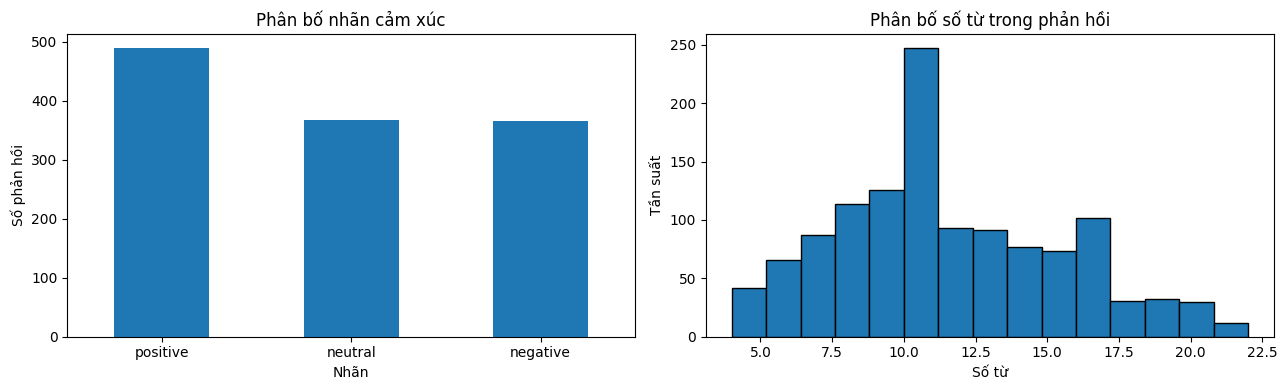

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
label_summary["Số lượng"].plot(kind="bar", ax=axes[0])
axes[0].set_title("Phân bố nhãn cảm xúc")
axes[0].set_xlabel("Nhãn")
axes[0].set_ylabel("Số phản hồi")
axes[0].tick_params(axis="x", rotation=0)

axes[1].hist(raw_words, bins=15, edgecolor="black")
axes[1].set_title("Phân bố số từ trong phản hồi")
axes[1].set_xlabel("Số từ")
axes[1].set_ylabel("Tần suất")
plt.tight_layout()
plt.show()

### 2.2. Kiểm tra các trường có sẵn

Dataset có thể có `preprocessed_text`, `emotion_tag` và các cột ngữ cảnh. Ta so sánh văn bản làm sạch với cột có sẵn; bảng chéo nhãn chỉ để rà soát, không tự động kết luận nhãn sai. Chỉ dùng `feedback_text` làm đầu vào và `sentiment_label` làm nhãn; không đưa ID/ngữ cảnh/nhãn phụ vào vectorizer.

In [4]:
raw_text = df[TEXT_COL].fillna("").astype(str)
special_summary = pd.Series({
    "Số văn bản có URL": raw_text.str.contains(r"https?://|www\.", case=False, regex=True).sum(),
    "Số văn bản có chữ số": raw_text.str.contains(r"\d", regex=True).sum(),
    "Số văn bản có dấu câu/ký tự đặc biệt": raw_text.str.contains(r"[^a-zA-Z0-9\s]", regex=True).sum()
}, name="Số văn bản")
display(special_summary.to_frame())

if "emotion_tag" in df.columns:
    print("Bảng chéo sentiment_label và emotion_tag (chỉ rà soát dữ liệu):")
    display(pd.crosstab(df[TARGET_COL], df["emotion_tag"], margins=True))

,Số văn bản
Số văn bản có URL,0
Số văn bản có chữ số,0
Số văn bản có dấu câu/ký tự đặc biệt,1223


Bảng chéo sentiment_label và emotion_tag (chỉ rà soát dữ liệu):


emotion_tag,anger,fear,joy,neutral,sadness,surprise,All
sentiment_label,,,,,,,
negative,61,57,64,62,57,65,366
neutral,63,66,55,61,59,64,368
positive,70,82,86,85,93,73,489
All,194,205,205,208,209,202,1223


## 3. Làm sạch văn bản

Các bước: chuyển chữ thường; loại URL nếu có; bỏ dấu câu/ký tự đặc biệt nhưng giữ chữ cái, chữ số; chuẩn hóa khoảng trắng; xóa khoảng trắng đầu/cuối.

**Không loại stopwords và không xóa chữ số ở cấu hình chính.** Từ phủ định như `not`, `no`, `never` có thể đảo nghĩa cảm xúc. Loại stopwords máy móc có thể làm mất tín hiệu; chữ số cũng có thể chứa thông tin. Nếu muốn thử loại bỏ, cần tạo thí nghiệm riêng và so sánh kết quả mô hình.

In [5]:
def clean_text(text):
    if pd.isna(text):
        return ""
    text = str(text).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["clean_text"] = df[TEXT_COL].apply(clean_text)
display(df[[TEXT_COL, "clean_text", TARGET_COL]].head(12))
print("Văn bản rỗng sau làm sạch:", int(df["clean_text"].str.strip().eq("").sum()))
print("URL còn lại:", int(df["clean_text"].str.contains(r"https?://|www\.", regex=True).sum()))

,feedback_text,clean_text,sentiment_label
0,Attack medical dog technology top several insi...,attack medical dog technology top several insi...,negative
1,Wait worry speak program child past beautiful ...,wait worry speak program child past beautiful ...,positive
2,Bank those report box your treatment accept in...,bank those report box your treatment accept in...,neutral
3,Can character million listen right amount ask ...,can character million listen right amount ask ...,positive
4,Good cost political street dream finish figure.,good cost political street dream finish figure,negative
5,Month leave doctor single vote say reach be sk...,month leave doctor single vote say reach be sk...,negative
6,Measure challenge series material I history le...,measure challenge series material i history le...,neutral
7,Small message what executive certain evidence ...,small message what executive certain evidence ...,positive
8,Civil eat memory become beyond interview fall ...,civil eat memory become beyond interview fall ...,negative
9,Machine tend simply beat which when remain why...,machine tend simply beat which when remain why...,negative


Văn bản rỗng sau làm sạch: 0
URL còn lại: 0


### 3.1. Đối chiếu với `preprocessed_text` có sẵn

In [6]:
if "preprocessed_text" in df.columns:
    preprocessed = df["preprocessed_text"].fillna("").astype(str)
    same = df["clean_text"].eq(preprocessed)
    print(f"Tỷ lệ khớp với preprocessed_text: {same.mean()*100:.2f}%")
    print("Số dòng không khớp:", int((~same).sum()))
    if (~same).any():
        display(df.loc[~same, [TEXT_COL, "clean_text", "preprocessed_text"]].head(10))
else:
    print("Dataset không có cột preprocessed_text.")

Tỷ lệ khớp với preprocessed_text: 100.00%
Số dòng không khớp: 0


### 3.2. So sánh độ dài trước và sau làm sạch

In [7]:
length_check = pd.DataFrame({
    "Ký tự trước": df[TEXT_COL].fillna("").astype(str).str.len(),
    "Ký tự sau": df["clean_text"].str.len(),
    "Số từ trước": df[TEXT_COL].fillna("").astype(str).str.split().str.len(),
    "Số từ sau": df["clean_text"].str.split().str.len()
})
display(length_check.describe().round(2))

,Ký tự trước,Ký tự sau,Số từ trước,Số từ sau
count,1223.00,1223.00,1223.00,1223.00
mean,75.16,74.16,11.45,11.45
std,26.24,26.24,3.91,3.91
min,22.00,21.00,4.00,4.00
25%,55.00,54.00,8.00,8.00
50%,72.00,71.00,11.00,11.00
75%,93.00,92.00,14.00,14.00
max,160.00,159.00,22.00,22.00


## 4. Chia train/test trước khi vector hóa

Dùng `stratify=y` để giữ tỷ lệ nhãn tương tự giữa hai tập. Vectorizer chỉ `fit` trên train; test chỉ `transform`, không tham gia xây dựng từ điển.

In [8]:
empty_mask = df["clean_text"].str.strip().eq("")
print("Số mẫu rỗng cần loại khỏi bước vector hóa:", int(empty_mask.sum()))
model_df = df.loc[~empty_mask].copy()

X = model_df["clean_text"]
y = model_df[TARGET_COL]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)

print(f"Train: {len(X_train)} mẫu ({len(X_train)/len(model_df):.1%})")
print(f"Test: {len(X_test)} mẫu ({len(X_test)/len(model_df):.1%})")
print("Tỷ lệ nhãn train (%):")
display((y_train.value_counts(normalize=True)*100).round(2).to_frame("Tỷ lệ"))
print("Tỷ lệ nhãn test (%):")
display((y_test.value_counts(normalize=True)*100).round(2).to_frame("Tỷ lệ"))

Số mẫu rỗng cần loại khỏi bước vector hóa: 0
Train: 978 mẫu (80.0%)
Test: 245 mẫu (20.0%)
Tỷ lệ nhãn train (%):


,Tỷ lệ
sentiment_label,
positive,39.98
neutral,30.06
negative,29.96


Tỷ lệ nhãn test (%):


,Tỷ lệ
sentiment_label,
positive,40.0
neutral,30.2
negative,29.8


## 5. Bag-of-Words (BoW) – CountVectorizer

BoW tạo ma trận đếm số lần xuất hiện của từ/cụm từ. Thử nghiệm Unigram `(1,1)` và Unigram + Bigram `(1,2)`. Cùng dùng `min_df=1`, `max_df=1.0`, `max_features=5000` để so sánh có kiểm soát.

In [9]:
bow_configs = {
    "BoW_Unigram": CountVectorizer(ngram_range=(1, 1), min_df=1, max_df=1.0, max_features=5000),
    "BoW_Unigram_Bigram": CountVectorizer(ngram_range=(1, 2), min_df=1, max_df=1.0, max_features=5000)
}
bow_results = {}
for name, vectorizer in bow_configs.items():
    Xtr = vectorizer.fit_transform(X_train)
    Xte = vectorizer.transform(X_test)
    bow_results[name] = {"vectorizer": vectorizer, "X_train": Xtr, "X_test": Xte}
    print(f"--- {name} ---")
    print("Train:", Xtr.shape, "| Test:", Xte.shape)
    print("Số đặc trưng:", len(vectorizer.get_feature_names_out()))
    print("20 đặc trưng đầu:", vectorizer.get_feature_names_out()[:20].tolist())

--- BoW_Unigram ---
Train: (978, 969) | Test: (245, 969)
Số đặc trưng: 969
20 đặc trưng đầu: ['ability', 'able', 'about', 'above', 'accept', 'according', 'account', 'across', 'act', 'action', 'activity', 'actually', 'add', 'address', 'administration', 'admit', 'adult', 'affect', 'after', 'again']
--- BoW_Unigram_Bigram ---
Train: (978, 5000) | Test: (245, 5000)
Số đặc trưng: 5000
20 đặc trưng đầu: ['ability', 'ability example', 'ability history', 'ability in', 'ability leader', 'ability leg', 'ability military', 'ability partner', 'ability push', 'ability service', 'ability set', 'ability side', 'ability speak', 'able', 'able above', 'able budget', 'able child', 'able fine', 'able green', 'able gun']


### 5.1. Các từ có tần suất cao trong BoW Unigram

,Từ,Tần suất trong train
0,history,25
1,hour,24
2,win,23
3,only,23
4,decision,23
5,push,22
6,perform,22
7,artist,21
8,someone,21
9,medical,21


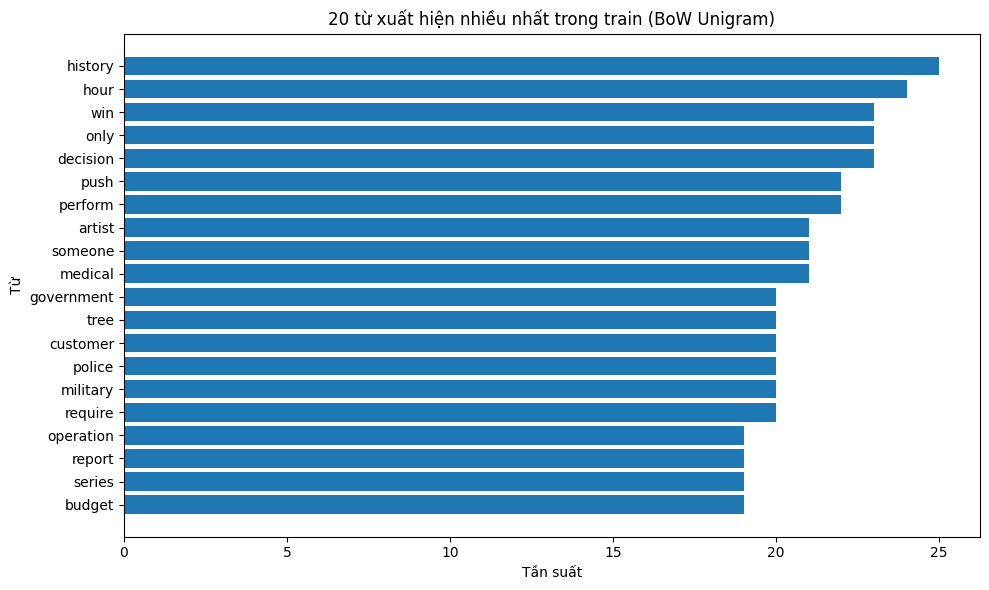

In [10]:
bow_vectorizer = bow_results["BoW_Unigram"]["vectorizer"]
bow_counts = np.asarray(bow_results["BoW_Unigram"]["X_train"].sum(axis=0)).ravel()
bow_terms = bow_vectorizer.get_feature_names_out()
top_idx = np.argsort(bow_counts)[::-1][:20]
top_bow = pd.DataFrame({
    "Từ": bow_terms[top_idx],
    "Tần suất trong train": bow_counts[top_idx].astype(int)
})
display(top_bow)

plt.figure(figsize=(10, 6))
plt.barh(top_bow["Từ"][::-1], top_bow["Tần suất trong train"][::-1])
plt.title("20 từ xuất hiện nhiều nhất trong train (BoW Unigram)")
plt.xlabel("Tần suất")
plt.ylabel("Từ")
plt.tight_layout()
plt.show()

## 6. TF-IDF – TfidfVectorizer

TF-IDF gán trọng số dựa trên tần suất từ trong văn bản và mức độ phổ biến của từ trong tập train. Dùng cùng cấu hình unigram/bigram để so sánh với BoW. Mặc định chuẩn hóa L2, sử dụng IDF và làm trơn IDF.

In [11]:
tfidf_configs = {
    "TFIDF_Unigram": TfidfVectorizer(
        ngram_range=(1, 1), min_df=1, max_df=1.0, max_features=5000,
        use_idf=True, smooth_idf=True, sublinear_tf=False
    ),
    "TFIDF_Unigram_Bigram": TfidfVectorizer(
        ngram_range=(1, 2), min_df=1, max_df=1.0, max_features=5000,
        use_idf=True, smooth_idf=True, sublinear_tf=False
    )
}
tfidf_results = {}
for name, vectorizer in tfidf_configs.items():
    Xtr = vectorizer.fit_transform(X_train)
    Xte = vectorizer.transform(X_test)
    tfidf_results[name] = {"vectorizer": vectorizer, "X_train": Xtr, "X_test": Xte}
    print(f"--- {name} ---")
    print("Train:", Xtr.shape, "| Test:", Xte.shape)
    print("Số đặc trưng:", len(vectorizer.get_feature_names_out()))
    print("20 đặc trưng đầu:", vectorizer.get_feature_names_out()[:20].tolist())

--- TFIDF_Unigram ---
Train: (978, 969) | Test: (245, 969)
Số đặc trưng: 969
20 đặc trưng đầu: ['ability', 'able', 'about', 'above', 'accept', 'according', 'account', 'across', 'act', 'action', 'activity', 'actually', 'add', 'address', 'administration', 'admit', 'adult', 'affect', 'after', 'again']


--- TFIDF_Unigram_Bigram ---
Train: (978, 5000) | Test: (245, 5000)
Số đặc trưng: 5000
20 đặc trưng đầu: ['ability', 'ability example', 'ability history', 'ability in', 'ability leader', 'ability leg', 'ability military', 'ability partner', 'ability push', 'ability service', 'ability set', 'ability side', 'ability speak', 'able', 'able above', 'able budget', 'able child', 'able fine', 'able green', 'able gun']


### 6.1. Quan sát IDF của các từ

In [12]:
tfidf_vectorizer = tfidf_results["TFIDF_Unigram"]["vectorizer"]
idf_table = pd.DataFrame({
    "Từ": tfidf_vectorizer.get_feature_names_out(),
    "IDF": tfidf_vectorizer.idf_
})
print("10 từ có IDF thấp nhất:")
display(idf_table.nsmallest(10, "IDF").reset_index(drop=True))
print("10 từ có IDF cao nhất:")
display(idf_table.nlargest(10, "IDF").reset_index(drop=True))

10 từ có IDF thấp nhất:


,Từ,IDF
0,history,4.628435
1,hour,4.667656
2,decision,4.708478
3,only,4.708478
4,win,4.708478
5,perform,4.751037
6,push,4.751037
7,artist,4.795489
8,someone,4.795489
9,customer,4.842009


10 từ có IDF cao nhất:


,Từ,IDF
0,assume,6.500237
1,remember,6.500237
2,take,6.500237
3,adult,6.277094
4,article,6.277094
5,contain,6.277094
6,free,6.277094
7,heart,6.277094
8,man,6.277094
9,policy,6.277094


## 7. So sánh các cấu hình BoW và TF-IDF

Bảng dưới đây mô tả kích thước biểu diễn và độ thưa của ma trận, **không phải chất lượng phân loại**. Muốn kết luận cấu hình nào dự đoán tốt hơn, cần huấn luyện cùng mô hình và so sánh F1-score, Precision, Recall, Accuracy, Confusion Matrix.

In [13]:
all_results = {**bow_results, **tfidf_results}
comparison_rows = []
for name, result in all_results.items():
    Xtr, Xte = result["X_train"], result["X_test"]
    total = Xtr.shape[0] * Xtr.shape[1]
    density = Xtr.nnz / total if total else 0
    comparison_rows.append({
        "Cấu hình": name,
        "Số mẫu train": Xtr.shape[0],
        "Số đặc trưng": Xtr.shape[1],
        "Kích thước test": str(Xte.shape),
        "Phần tử khác 0 (train)": int(Xtr.nnz),
        "Mật độ train (%)": round(density*100, 3),
        "Độ thưa train (%)": round((1-density)*100, 3)
    })
comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)

,Cấu hình,Số mẫu train,Số đặc trưng,Kích thước test,Phần tử khác 0 (train),Mật độ train (%),Độ thưa train (%)
0,BoW_Unigram,978,969,"(245, 969)",11109,1.172,98.828
1,BoW_Unigram_Bigram,978,5000,"(245, 5000)",15184,0.311,99.689
2,TFIDF_Unigram,978,969,"(245, 969)",11109,1.172,98.828
3,TFIDF_Unigram_Bigram,978,5000,"(245, 5000)",15184,0.311,99.689


### 7.1. Hướng diễn giải
- Bigram thêm thông tin về cặp từ liên tiếp, có thể nhận diện một số cụm từ; đổi lại số đặc trưng và độ thưa thường tăng.
- BoW giữ số lần xuất hiện; TF-IDF điều chỉnh trọng số theo mức độ phổ biến của từ trong tập train.
- Không thể chọn phương pháp tốt nhất chỉ dựa vào số chiều hoặc độ thưa.
- Nếu số chiều quá lớn, có thể thử `min_df=2` hoặc giảm `max_features` ở thí nghiệm bổ sung; cần báo cáo rõ cấu hình.

## 8. Kiểm tra nhất quán train/test và chống data leakage

In [14]:
for name, result in all_results.items():
    assert result["X_train"].shape[1] == result["X_test"].shape[1]
    print(f"{name}: train={result['X_train'].shape}, test={result['X_test'].shape}; fit chỉ trên train.")
print("Đã kiểm tra: số chiều train/test khớp ở tất cả cấu hình.")

BoW_Unigram: train=(978, 969), test=(245, 969); fit chỉ trên train.
BoW_Unigram_Bigram: train=(978, 5000), test=(245, 5000); fit chỉ trên train.
TFIDF_Unigram: train=(978, 969), test=(245, 969); fit chỉ trên train.
TFIDF_Unigram_Bigram: train=(978, 5000), test=(245, 5000); fit chỉ trên train.
Đã kiểm tra: số chiều train/test khớp ở tất cả cấu hình.


## 9. Lưu sản phẩm để bàn giao

Tệp đầu ra gồm dữ liệu đã làm sạch, ma trận sparse train/test, vectorizer đã fit, nhãn theo đúng thứ tự và chỉ số dòng gốc để truy vết. Thành viên mô hình phải dùng đúng ma trận cùng cấu hình với `y_train`/`y_test`.

In [15]:
OUTPUT_DIR = Path("member2_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

model_df[[TEXT_COL, "clean_text", TARGET_COL]].to_csv(
    OUTPUT_DIR / "cleaned_feedback.csv", index=False, encoding="utf-8-sig"
)
y_train.rename(TARGET_COL).to_csv(OUTPUT_DIR / "y_train.csv", index=False, encoding="utf-8-sig")
y_test.rename(TARGET_COL).to_csv(OUTPUT_DIR / "y_test.csv", index=False, encoding="utf-8-sig")

pd.DataFrame({
    "split": ["train"] * len(X_train) + ["test"] * len(X_test),
    "original_index": list(X_train.index) + list(X_test.index)
}).to_csv(OUTPUT_DIR / "split_indices.csv", index=False)

for name, result in all_results.items():
    save_npz(OUTPUT_DIR / f"{name}_train.npz", result["X_train"])
    save_npz(OUTPUT_DIR / f"{name}_test.npz", result["X_test"])
    joblib.dump(result["vectorizer"], OUTPUT_DIR / f"{name}_vectorizer.joblib")

config = {
    "text_column": TEXT_COL,
    "target_column": TARGET_COL,
    "test_size": TEST_SIZE,
    "random_state": RANDOM_STATE,
    "stratify": True,
    "stopwords_removed": False,
    "digits_removed": False,
    "vectorizers": {
        "BoW_Unigram": {"ngram_range": [1, 1], "min_df": 1, "max_df": 1.0, "max_features": 5000},
        "BoW_Unigram_Bigram": {"ngram_range": [1, 2], "min_df": 1, "max_df": 1.0, "max_features": 5000},
        "TFIDF_Unigram": {"ngram_range": [1, 1], "min_df": 1, "max_df": 1.0, "max_features": 5000},
        "TFIDF_Unigram_Bigram": {"ngram_range": [1, 2], "min_df": 1, "max_df": 1.0, "max_features": 5000}
    }
}
with open(OUTPUT_DIR / "experiment_config.json", "w", encoding="utf-8") as f:
    json.dump(config, f, ensure_ascii=False, indent=2)

print("Đã lưu:", OUTPUT_DIR.resolve())
for p in sorted(OUTPUT_DIR.iterdir()):
    print("-", p.name)

Đã lưu: /mnt/data/member2_outputs
- BoW_Unigram_Bigram_test.npz
- BoW_Unigram_Bigram_train.npz
- BoW_Unigram_Bigram_vectorizer.joblib
- BoW_Unigram_test.npz
- BoW_Unigram_train.npz
- BoW_Unigram_vectorizer.joblib
- TFIDF_Unigram_Bigram_test.npz
- TFIDF_Unigram_Bigram_train.npz
- TFIDF_Unigram_Bigram_vectorizer.joblib
- TFIDF_Unigram_test.npz
- TFIDF_Unigram_train.npz
- TFIDF_Unigram_vectorizer.joblib
- cleaned_feedback.csv
- experiment_config.json
- split_indices.csv
- y_test.csv
- y_train.csv


## 10. Kết luận phần Thành viên 2

Sau khi chạy notebook, dùng số liệu thực tế từ các bảng để hoàn thiện báo cáo:
- Bộ dữ liệu có 1.223 dòng, 11 cột; `feedback_text` là văn bản đầu vào và `sentiment_label` là nhãn.
- Phân bố nhãn và độ dài văn bản được thống kê/biểu diễn tại Mục 2.
- Văn bản được làm sạch bằng các bước đã mô tả; đối chiếu `clean_text` với `preprocessed_text` để xác minh.
- Đã thử BoW và TF-IDF, mỗi phương pháp có unigram và unigram/bigram.
- Vectorizer chỉ fit trên train nhằm hạn chế data leakage.

**Phối hợp thành viên huấn luyện:** Dùng các ma trận đã lưu để chạy cùng một mô hình baseline (ví dụ Multinomial Naive Bayes) trên từng cấu hình. So sánh Accuracy, Precision, Recall, F1-score và Confusion Matrix. Chỉ sau đó mới kết luận cấu hình nào tốt hơn.

**Giới hạn:** Notebook này phụ trách tiền xử lý và biểu diễn văn bản, không tự kết luận chất lượng phân loại khi chưa huấn luyện/đánh giá mô hình. Không tự ý sửa nhãn khi chưa có căn cứ từ nguồn dữ liệu hoặc xác nhận của giảng viên.